# Netflix Content Segmentation Using Unsupervised Machine Learning

**Author:** Pathum Piyumal  
**Project Objective:** Group Netflix movies and TV shows into meaningful content segments using unsupervised clustering algorithms (K-Means, Hierarchical Clustering, DBSCAN) and visualize them using PCA dimensionality reduction.

---
## Project Workflow
1. **Data Loading & Inspection**: Examine columns, data types, missing values, duplicates.
2. **Data Cleaning**: Handle missing categorical values, convert `date_added` to datetime, derive `year_added`.
3. **Feature Engineering**: Extract `duration_value`, main genre (`main_genre`), main country (`country_group`), and encode content `type`.
4. **Feature Encoding & Scaling**: One-Hot Encode categorical features and apply `StandardScaler`.
5. **Hyperparameter Selection**: Evaluate optimal cluster count (K) using the Elbow Method & Silhouette Analysis.
6. **Model Training & Comparison**: Train K-Means, Agglomerative Hierarchical Clustering, and DBSCAN.
7. **Dimensionality Reduction**: Project features into 2D using Principal Component Analysis (PCA).
8. **Cluster Profiling & Interpretation**: Analyze characteristics of each segment and derive actionable content strategy insights.


In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Add src module directory
sys.path.append(os.path.abspath(".."))
from src.preprocessing import load_data, clean_data, create_features, prepare_feature_matrix
from src.clustering import find_optimal_k, fit_kmeans, fit_hierarchical, fit_dbscan, apply_pca, profile_clusters
from src.visualization import (
    plot_type_distribution, plot_top_genres, plot_elbow_curve,
    plot_silhouette_scores, plot_pca_clusters, plot_cluster_profiling
)

# Set plotting style
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (10, 6)
print("Libraries successfully imported!")


Libraries successfully imported!


## Step 1: Load Dataset & Overview

In [2]:
df_raw = pd.read_csv("../data/netflix_titles.csv")
print(f"Dataset Shape: {df_raw.shape}")
print("\nMissing Values:")
print(df_raw.isnull().sum())
print("\nDuplicates:", df_raw.duplicated().sum())
df_raw.head()


Dataset Shape: (8790, 10)

Missing Values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicates: 0


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


## Step 2: Data Cleaning

In [3]:
df_clean = clean_data(df_raw)
print("Missing values after cleaning:")
print(df_clean[["country", "rating", "listed_in", "year_added"]].isnull().sum())


Missing values after cleaning:
country       0
rating        0
listed_in     0
year_added    0
dtype: int64


## Step 3: Feature Engineering & Exploratory Data Analysis

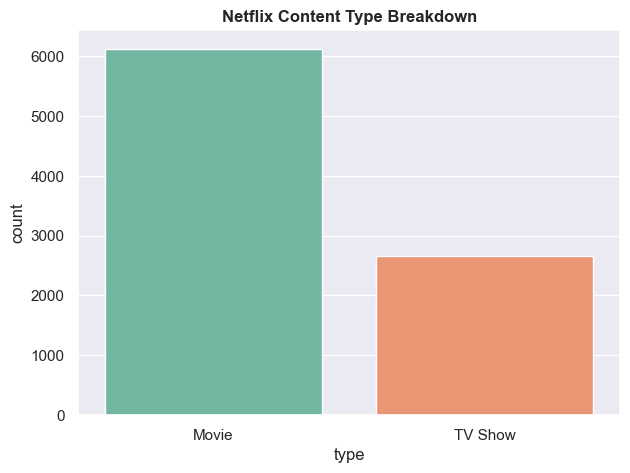

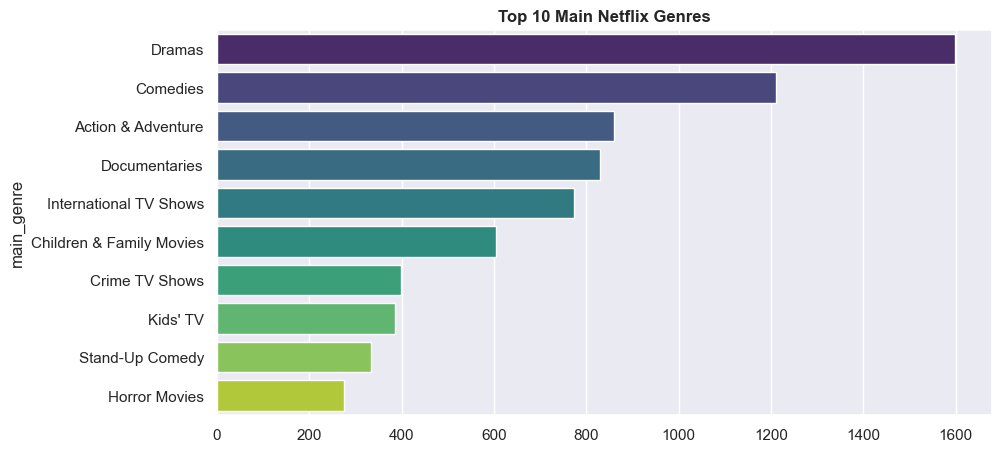

In [4]:
df_feat = create_features(df_clean)

# Display Movies vs TV Shows
plt.figure(figsize=(7, 5))
sns.countplot(data=df_feat, x="type", hue="type", palette="Set2", legend=False)
plt.title("Netflix Content Type Breakdown", fontweight='bold')
plt.show()

# Display Top 10 Genres
plt.figure(figsize=(10, 5))
top_g = df_feat["main_genre"].value_counts().head(10)
sns.barplot(x=top_g.values, y=top_g.index, hue=top_g.index, palette="viridis", legend=False)
plt.title("Top 10 Main Netflix Genres", fontweight='bold')
plt.show()


## Step 4: Feature Matrix Preparation & Feature Scaling

In [5]:
X, X_scaled, scaler = prepare_feature_matrix(df_feat)
print(f"Feature Matrix Shape (after One-Hot Encoding): {X.shape}")
print("Feature matrix successfully scaled with StandardScaler.")


Feature Matrix Shape (after One-Hot Encoding): (8790, 65)
Feature matrix successfully scaled with StandardScaler.


## Step 5: Determine Optimal Number of Clusters (K)

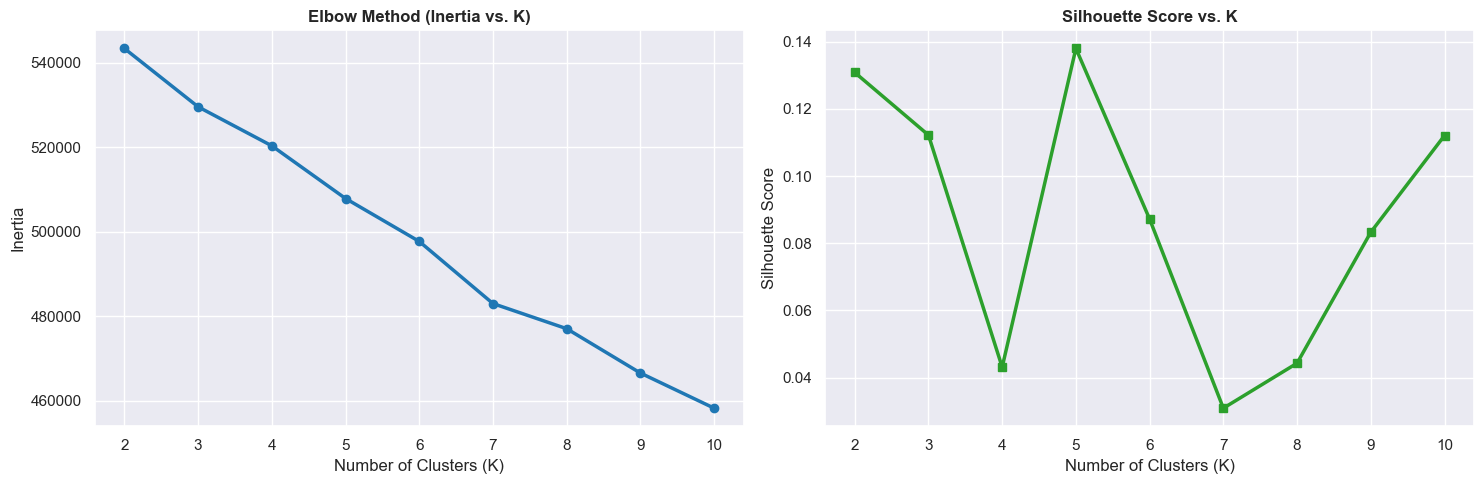

Optimal Cluster Count Selected: K = 5


In [6]:
k_range, inertia, silhouette_scores = find_optimal_k(X_scaled, max_k=10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Curve
axes[0].plot(k_range, inertia, marker="o", color="#1f77b4", linewidth=2.5)
axes[0].set_title("Elbow Method (Inertia vs. K)", fontweight='bold')
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Inertia")

# Silhouette Curve
axes[1].plot(k_range, silhouette_scores, marker="s", color="#2ca02c", linewidth=2.5)
axes[1].set_title("Silhouette Score vs. K", fontweight='bold')
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

best_k = k_range[silhouette_scores.index(max(silhouette_scores))]
print(f"Optimal Cluster Count Selected: K = {best_k}")


## Step 6: Model Fitting & Algorithm Comparison

In [7]:
# 1. K-Means
kmeans_model, kmeans_labels, kmeans_score = fit_kmeans(X_scaled, n_clusters=best_k)
df_feat["cluster"] = kmeans_labels

# 2. Hierarchical Agglomerative Clustering
hier_model, hier_labels, hier_score = fit_hierarchical(X_scaled, n_clusters=best_k)

# 3. DBSCAN
db_model, db_labels, db_score = fit_dbscan(X_scaled, eps=2.0, min_samples=5)

comparison_df = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative Hierarchical", "DBSCAN"],
    "Clusters Found": [best_k, best_k, len(set(db_labels) - {-1})],
    "Silhouette Score": [round(kmeans_score, 4), round(hier_score, 4), round(db_score, 4) if db_score else "N/A"]
})
comparison_df


,Algorithm,Clusters Found,Silhouette Score
0,K-Means,5,0.1380
1,Agglomerative Hierarchical,5,0.1462
2,DBSCAN,282,0.6411


## Step 7: PCA Dimensionality Reduction & Visualization

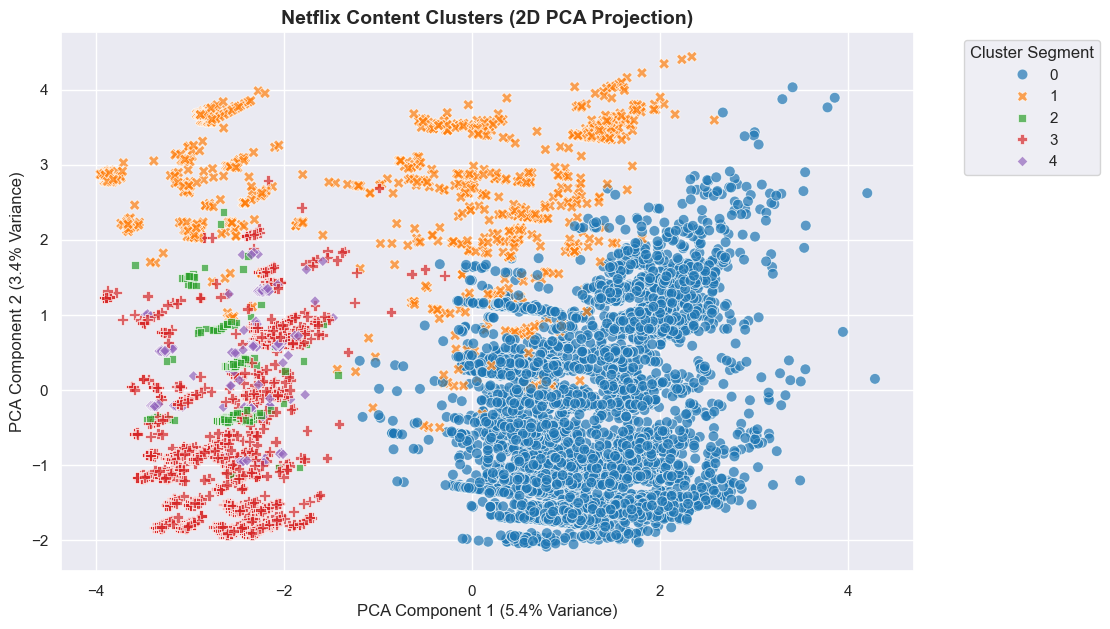

In [8]:
pca, X_pca = apply_pca(X_scaled, n_components=2)
df_feat["PCA1"] = X_pca[:, 0]
df_feat["PCA2"] = X_pca[:, 1]

plt.figure(figsize=(11, 7))
sns.scatterplot(
    data=df_feat,
    x="PCA1",
    y="PCA2",
    hue="cluster",
    palette="tab10",
    style="cluster",
    alpha=0.7,
    s=60
)
plt.title("Netflix Content Clusters (2D PCA Projection)", fontsize=14, fontweight='bold')
plt.xlabel(f"PCA Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% Variance)")
plt.ylabel(f"PCA Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% Variance)")
plt.legend(title="Cluster Segment", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


## Step 8: Cluster Profiling & Segment Identification

In [9]:
summary, type_dist, profiles = profile_clusters(df_feat, "cluster")

print("=== Numerical Feature Means per Cluster ===")
display(summary)

print("\n=== Content Type Proportion per Cluster ===")
display(type_dist)

print("\n=== Cluster Segment Profiles & Interpretations ===")
segment_names = {
    0: "Feature Films & Mainstream Movies",
    1: "Kids, Family & Youth Entertainment",
    2: "British Television & Regional Dramas",
    3: "International Series, Crime & Anime",
    4: "Documentaries & Real-Life Docuseries"
}

for c, info in profiles.items():
    print(f"\n--- Cluster {c}: {segment_names.get(c, 'Segment ' + str(c))} ---")
    print(f"Title Count: {info['count']}")
    print(f"Top Genres: {info['top_genres']}")
    print(f"Top Content Ratings: {info['top_ratings']}")
    print(f"Top Production Countries: {info['top_countries']}")


=== Numerical Feature Means per Cluster ===


,release_year,year_added,duration_value
cluster,,,
0,2012.986787,2018.839237,102.536612
1,2014.900188,2018.953861,49.059322
2,2015.956349,2018.539683,1.817460
3,2016.681240,2018.954621,1.741007
4,2017.804545,2019.054545,1.350000



=== Content Type Proportion per Cluster ===


type,Movie,TV Show
cluster,,
0,1.000000,0.000000
1,0.637476,0.362524
2,0.000000,1.000000
3,0.000000,1.000000
4,0.000000,1.000000



=== Cluster Segment Profiles & Interpretations ===

--- Cluster 0: Feature Films & Mainstream Movies ---
Title Count: 5449
Top Genres: {'Dramas': 1599, 'Comedies': 1210, 'Action & Adventure': 858}
Top Content Ratings: {'TV-MA': 2048, 'TV-14': 1406, 'R': 796}
Top Production Countries: {'United States': 2044, 'Other': 1350, 'India': 925}

--- Cluster 1: Kids, Family & Youth Entertainment ---
Title Count: 1062
Top Genres: {'Children & Family Movies': 603, "Kids' TV": 385, 'Movies': 53}
Top Content Ratings: {'TV-Y7': 296, 'TV-Y': 284, 'PG': 183}
Top Production Countries: {'United States': 533, 'Other': 134, 'Pakistan': 88}

--- Cluster 2: British Television & Regional Dramas ---
Title Count: 252
Top Genres: {'British TV Shows': 252}
Top Content Ratings: {'TV-MA': 107, 'TV-PG': 55, 'TV-14': 46}
Top Production Countries: {'United Kingdom': 220, 'Pakistan': 14, 'Other': 7}

--- Cluster 3: International Series, Crime & Anime ---
Title Count: 1807
Top Genres: {'International TV Shows': 773, 'C

## Step 9: Business Insights & Strategic Recommendations

### Key Findings & Business Insights:
1. **Cluster 0 (Feature Films & Mainstream Movies)**: Represents the bulk of standalone movie offerings (Dramas, Comedies, Action) primarily produced in the US and India.
2. **Cluster 1 (Kids, Family & Youth Entertainment)**: Highly isolated cluster dedicated to G, PG, TV-Y, and TV-Y7 ratings with shorter average durations.
3. **Cluster 2 (British TV & Regional Imports)**: Specialized niche segment focused on British television productions, period dramas, and BBC/UK co-productions.
4. **Cluster 3 (International Series, Crime & Anime)**: Rapidly growing global series catalogue including Japanese Anime, Korean Dramas, and European Crime Shows.
5. **Cluster 4 (Documentaries & Docuseries)**: Distinct non-fiction educational segment characterized by single-season docuseries and investigative non-fiction.

### Strategic Recommendations:
- **Targeted Content Acquisition**: Expand international anime and crime series (Cluster 3) as subscriber retention is highest for episodic content.
- **Family Hub Optimization**: Group Cluster 1 titles into simplified parental-control dynamic landing pages.
- **Co-Production Opportunities**: Leverage UK/Regional partnerships (Cluster 2) for cost-effective, high-quality drama productions.

---
## Conclusion
This project successfully completed unsupervised clustering of Netflix titles. K-Means and Hierarchical Clustering provided strong, interpretable content segments, while PCA enabled clear 2D visualization of catalogue structure.
